# Рекомендательная система фильмов CineMatch

**Что делает ноутбук**
1. Загружает официальные IMDb Datasets и формирует топ-200 фильмов по рейтингу и числу голосов.
2. Получает описания и постеры через TMDB API по IMDb ID (без HTML-парсинга Википедии).
3. Загружает MovieLens и связывает пользовательские оценки с фильмами.
4. Реализует четыре функции из учебного задания:
   - топ-10 по взвешенному рейтингу;
   - рекомендации по жанру;
   - рекомендации по содержанию (по названию фильма);
   - коллаборативные рекомендации для пользователя.
5. Сравнивает варианты контентной и коллаборативной моделей.
6. Создаёт единый сервис `MovieRecommender` и сохраняет артефакты для FastAPI и GUI.

## 0. Импорты и настройки

In [2]:
import os
from getpass import getpass

import io
import json
import time
import zipfile
import difflib
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.model_selection import train_test_split

warnings.filterwarnings("ignore")
pd.set_option("display.max_colwidth", 100)
pd.set_option("display.width", 160)

DATA_DIR = Path("data")
DATA_DIR.mkdir(exist_ok=True)

ARTIFACTS_DIR = Path("artifacts")
ARTIFACTS_DIR.mkdir(exist_ok=True)

RANDOM_STATE = 42
N_TOP = 200
MIN_IMDB_VOTES = 25000

print("Данные:", DATA_DIR.resolve())
print("Артефакты:", ARTIFACTS_DIR.resolve())

Данные: C:\Users\Svetlana\Project\movie_recommender\data
Артефакты: C:\Users\Svetlana\Project\movie_recommender\artifacts


## 1. Получение топ-200 фильмов IMDb и метаданных TMDB

Рейтинг и количество голосов берём из официального IMDb Datasets:
- `title.ratings.tsv.gz` — средний рейтинг и число голосов;
- `title.basics.tsv.gz` — название, год, жанры и продолжительность.

Далее объединяем таблицы по IMDb ID и выбираем 200 фильмов с наибольшим рейтингом среди фильмов, набравших не менее `MIN_IMDB_VOTES` голосов.

**Описания и постеры получаем через TMDB API** по внешнему IMDb ID. HTML-страницы и парсинг Википедии не используются. Результат после каждого фильма сохраняется в `data/top200_tmdb.csv`, поэтому повторный запуск продолжает работу с локального кэша.

Для запросов нужен TMDB API Read Access Token в переменной окружения `TMDB_READ_TOKEN`. Токен не записывается в файл ноутбука.

In [2]:
TOP_IMDB_CSV = DATA_DIR / "top200_imdb.csv"

IMDB_RATINGS_URL = (
    "https://datasets.imdbws.com/title.ratings.tsv.gz"
)

IMDB_BASICS_URL = (
    "https://datasets.imdbws.com/title.basics.tsv.gz"
)

print("Папка данных:", DATA_DIR.resolve())
print("Файл результатов:", TOP_IMDB_CSV.resolve())

Папка данных: C:\Users\Svetlana\Project\movie_recommender\data
Файл результатов: C:\Users\Svetlana\Project\movie_recommender\data\top200_imdb.csv


In [3]:
# Отсекаем фильмы с малым числом голосов: их рейтинг менее устойчив.
print("Загружаем рейтинги IMDb...")

imdb_ratings = pd.read_csv(
    IMDB_RATINGS_URL,
    sep="\t",
    compression="gzip",
    na_values="\\N"
)

imdb_ratings["averageRating"] = pd.to_numeric(
    imdb_ratings["averageRating"],
    errors="coerce"
)

imdb_ratings["numVotes"] = pd.to_numeric(
    imdb_ratings["numVotes"],
    errors="coerce"
)

imdb_ratings = imdb_ratings[
    imdb_ratings["numVotes"] >= 25000
].copy()

print("Количество записей:", len(imdb_ratings))

display(imdb_ratings.head())

Загружаем рейтинги IMDb...
Количество записей: 9502


,tconst,averageRating,numVotes
408,tt0000417,8.1,62108
1994,tt0004972,6.0,28656
3396,tt0010323,8.0,77364
3964,tt0012349,8.2,147650
4266,tt0013442,7.8,125011


In [4]:
# Берём ограниченный список кандидатов, чтобы не читать весь большой файл IMDb целиком.
print("Загружаем информацию о фильмах...")

candidates = (
    imdb_ratings
    .sort_values(
        ["averageRating", "numVotes"],
        ascending=[False, False]
    )
    .head(10000)
    .copy()
)

candidate_ids = set(candidates["tconst"])

print("Кандидатов:", len(candidate_ids))

Загружаем информацию о фильмах...
Кандидатов: 9502


In [5]:
# Читаем IMDb basics частями (chunks), чтобы не загружать весь архив в память.
basics_parts = []

for chunk in pd.read_csv(
    IMDB_BASICS_URL,
    sep="\t",
    compression="gzip",
    usecols=[
        "tconst",
        "titleType",
        "primaryTitle",
        "startYear",
        "runtimeMinutes",
        "genres",
        "isAdult"
    ],
    na_values="\\N",
    chunksize=500000,
    low_memory=False
):
    
    chunk = chunk[
        (chunk["titleType"] == "movie") &
        (chunk["isAdult"] == 0) &
        (chunk["tconst"].isin(candidate_ids))
    ]

    if not chunk.empty:
        basics_parts.append(chunk)

imdb_basics = pd.concat(
    basics_parts,
    ignore_index=True
)

print("Найдено фильмов:", len(imdb_basics))

display(imdb_basics.head())

Найдено фильмов: 7318


,tconst,titleType,primaryTitle,isAdult,startYear,runtimeMinutes,genres
0,tt0004972,movie,The Birth of a Nation,0,1915.0,195.0,"Drama,War"
1,tt0010323,movie,The Cabinet of Dr. Caligari,0,1920.0,67.0,"Horror,Mystery,Thriller"
2,tt0012349,movie,The Kid,0,1921.0,68.0,"Comedy,Drama,Family"
3,tt0013442,movie,Nosferatu,0,1922.0,95.0,"Fantasy,Horror"
4,tt0014429,movie,Safety Last!,0,1923.0,74.0,"Action,Comedy,Romance"


In [6]:
# Сопоставляем IMDb и TMDB по точному IMDb ID; кэш позволяет не повторять уже выполненные API-запросы.
TMDB_API_BASE_URL = "https://api.themoviedb.org/3"
TMDB_IMAGE_BASE_URL = "https://image.tmdb.org/t/p/w500"

TMDB_ACCESS_TOKEN = os.getenv("TMDB_READ_TOKEN")
if not TMDB_ACCESS_TOKEN:
    TMDB_ACCESS_TOKEN = getpass("Вставь TMDB Read Access Token: ").strip()

if not TMDB_ACCESS_TOKEN:
    raise RuntimeError("TMDB Read Access Token не введён.")

tmdb_session = requests.Session()
tmdb_session.headers.update({
    "Authorization": f"Bearer {TMDB_ACCESS_TOKEN}",
    "accept": "application/json"
})

top = imdb_basics.merge(
    candidates[["tconst", "averageRating", "numVotes"]],
    on="tconst",
    how="inner"
).copy()

top = top.rename(columns={
    "tconst": "imdb_id",
    "primaryTitle": "title_imdb",
    "startYear": "year",
    "runtimeMinutes": "runtime_minutes",
    "averageRating": "imdb_rating",
    "numVotes": "imdb_votes"
})

top["imdb_rating"] = pd.to_numeric(top["imdb_rating"], errors="coerce")
top["imdb_votes"] = pd.to_numeric(top["imdb_votes"], errors="coerce")
top["year"] = pd.to_numeric(top["year"], errors="coerce")

top = (
    top.dropna(subset=["imdb_rating", "imdb_votes", "title_imdb"])
       .sort_values(["imdb_rating", "imdb_votes"], ascending=[False, False])
       .drop_duplicates("imdb_id")
       .head(N_TOP)
       .reset_index(drop=True)
)
top.insert(0, "rank", range(1, len(top) + 1))

TMDB_CACHE_FILE = DATA_DIR / "top200_tmdb.csv"
for col in ["overview", "poster_url", "tmdb_id", "tmdb_title", "tmdb_genres"]:
    if col not in top.columns:
        top[col] = ""

if TMDB_CACHE_FILE.exists():
    previous = pd.read_csv(TMDB_CACHE_FILE).drop_duplicates("imdb_id", keep="last")
    previous = previous.set_index("imdb_id")
    for col in ["overview", "poster_url", "tmdb_id", "tmdb_title", "tmdb_genres"]:
        if col in previous.columns:
            cache = previous[col].to_dict()
            top[col] = top.apply(
                lambda row: cache.get(row["imdb_id"], row[col])
                if pd.notna(cache.get(row["imdb_id"], row[col]))
                and str(cache.get(row["imdb_id"], row[col])).strip()
                else row[col],
                axis=1
            )

def tmdb_find_by_imdb(imdb_id):
    """Находит фильм TMDB по точному внешнему IMDb ID."""
    url = f"{TMDB_API_BASE_URL}/find/{imdb_id}"
    params = {"external_source": "imdb_id"}
    for attempt in range(4):
        try:
            response = tmdb_session.get(url, params=params, timeout=25)
            if response.status_code == 429:
                wait = int(response.headers.get("Retry-After", "2"))
                time.sleep(min(wait, 30))
                continue
            response.raise_for_status()
            results = response.json().get("movie_results", [])
            return results[0] if results else None
        except requests.RequestException:
            if attempt == 3:
                raise
            time.sleep(2 ** attempt)
    return None

total = len(top)
for idx, row in top.iterrows():
    already_done = (
        isinstance(row["overview"], str) and bool(row["overview"].strip())
        and isinstance(row["tmdb_id"], (int, float, np.integer, np.floating))
        and pd.notna(row["tmdb_id"])
    )
    if already_done:
        print(f"[{idx + 1}/{total}] {row['title_imdb']} — из локального кэша")
        continue

    print(f"[{idx + 1}/{total}] TMDB: {row['title_imdb']} ({row['imdb_id']})")
    result = tmdb_find_by_imdb(row["imdb_id"])

    if result:
        top.at[idx, "tmdb_id"] = result.get("id", "")
        top.at[idx, "tmdb_title"] = result.get("title", "")
        top.at[idx, "overview"] = result.get("overview", "") or ""
        poster_path = result.get("poster_path")
        top.at[idx, "poster_url"] = f"{TMDB_IMAGE_BASE_URL}{poster_path}" if poster_path else ""
        top.at[idx, "tmdb_genres"] = ""
    else:
        print("  Фильм не найден в TMDB; оставляем описание/постер пустыми.")

    top.to_csv(TMDB_CACHE_FILE, index=False)
    time.sleep(0.05)

top.to_csv(TMDB_CACHE_FILE, index=False)

print("\nСбор завершён")
print("Фильмов:", len(top))
print("Описаний:", top["overview"].fillna("").astype(str).str.strip().ne("").sum())
print("Постеров:", top["poster_url"].fillna("").astype(str).str.strip().ne("").sum())
print("Файл кэша:", TMDB_CACHE_FILE.resolve())
display(top[["rank", "title_imdb", "year", "imdb_rating", "overview", "poster_url"]].head(10))

Вставь TMDB Read Access Token:  ········


[1/200] The Shawshank Redemption — из локального кэша
[2/200] The Godfather — из локального кэша
[3/200] The Dark Knight — из локального кэша
[4/200] The Chaos Class — из локального кэша
[5/200] The Lord of the Rings: The Return of the King — из локального кэша
[6/200] Schindler's List — из локального кэша
[7/200] The Godfather Part II — из локального кэша
[8/200] 12 Angry Men — из локального кэша
[9/200] The Lord of the Rings: The Fellowship of the Ring — из локального кэша
[10/200] Attack on Titan: The Last Attack — из локального кэша
[11/200] David Attenborough: A Life on Our Planet — из локального кэша
[12/200] Tosun Pasha — из локального кэша
[13/200] Inception — из локального кэша
[14/200] Fight Club — из локального кэша
[15/200] Forrest Gump — из локального кэша
[16/200] Pulp Fiction — из локального кэша
[17/200] The Lord of the Rings: The Two Towers — из локального кэша
[18/200] The Good, the Bad and the Ugly — из локального кэша
[19/200] Punjab '95 — из локального кэша
[20/200

,rank,title_imdb,year,imdb_rating,overview,poster_url
0,1,The Shawshank Redemption,1994.0,9.3,"Imprisoned in the 1940s for the double murder of his wife and her lover, upstanding banker Andy ...",https://image.tmdb.org/t/p/w500/9cqNxx0GxF0bflZmeSMuL5tnGzr.jpg
1,2,The Godfather,1972.0,9.2,"Spanning the years 1945 to 1955, a chronicle of the fictional Italian-American Corleone crime fa...",https://image.tmdb.org/t/p/w500/3bhkrj58Vtu7enYsRolD1fZdja1.jpg
2,3,The Dark Knight,2008.0,9.1,Batman raises the stakes in his war on crime. With the help of Lt. Jim Gordon and District Attor...,https://image.tmdb.org/t/p/w500/qJ2tW6WMUDux911r6m7haRef0WH.jpg
3,4,The Chaos Class,1975.0,9.1,A group of affluent private school slackers enjoy a prankster lifestyle until a tough new discip...,https://image.tmdb.org/t/p/w500/t2xLuEeZhy4uyiWIFT9D4mmyEA8.jpg
4,5,The Lord of the Rings: The Return of the King,2003.0,9.0,"As armies mass for a final battle that will decide the fate of the world--and powerful, ancient ...",https://image.tmdb.org/t/p/w500/rCzpDGLbOoPwLjy3OAm5NUPOTrC.jpg
5,6,Schindler's List,1993.0,9.0,The true story of how businessman Oskar Schindler saved over a thousand Jewish lives from the Na...,https://image.tmdb.org/t/p/w500/sF1U4EUQS8YHUYjNl3pMGNIQyr0.jpg
6,7,The Godfather Part II,1974.0,9.0,"In the continuing saga of the Corleone crime family, a young Vito Corleone grows up in Sicily an...",https://image.tmdb.org/t/p/w500/8a1lJs7mFyGhGhZZDT1azJUoQiZ.jpg
7,8,12 Angry Men,1957.0,9.0,The defense and the prosecution have rested and the jury is filing into the jury room to decide ...,https://image.tmdb.org/t/p/w500/zhG3vKWyDRaZYoaww1UVAi29T9h.jpg
8,9,The Lord of the Rings: The Fellowship of the Ring,2001.0,8.9,"Young hobbit Frodo Baggins, after inheriting a mysterious ring from his uncle Bilbo, must leave ...",https://image.tmdb.org/t/p/w500/6oom5QYQ2yQTMJIbnvbkBL9cHo6.jpg
9,10,Attack on Titan: The Last Attack,2024.0,8.9,A colossal-sized omnibus film bringing together the last two episodes of Attack on Titan in the ...,https://image.tmdb.org/t/p/w500/wgwldDDlTDDMrluOMkpSA8lyKjv.jpg


In [8]:
print("Количество фильмов:", len(top))
print("Количество столбцов:", len(top.columns))

print("\nНазвания столбцов:")
print(top.columns.tolist())

print("\nПроверка пропусков:")
print(top.isna().sum())

print("\nТоп-10 фильмов:")
display(
    top[[
        "rank",
        "title_imdb",
        "imdb_rating",
        "imdb_votes"
    ]].head(10)
)
print("\nПроверка описаний:")
print("Пустых описаний:", top["overview"].fillna("").str.strip().eq("").sum())


Количество фильмов: 200
Количество столбцов: 15

Названия столбцов:
['rank', 'imdb_id', 'titleType', 'title_imdb', 'isAdult', 'year', 'runtime_minutes', 'genres', 'imdb_rating', 'imdb_votes', 'overview', 'poster_url', 'tmdb_id', 'tmdb_title', 'tmdb_genres']

Проверка пропусков:
rank               0
imdb_id            0
titleType          0
title_imdb         0
isAdult            0
year               0
runtime_minutes    0
genres             0
imdb_rating        0
imdb_votes         0
overview           0
poster_url         0
tmdb_id            0
tmdb_title         0
tmdb_genres        0
dtype: int64

Топ-10 фильмов:


,rank,title_imdb,imdb_rating,imdb_votes
0,1,The Shawshank Redemption,9.3,3258815
1,2,The Godfather,9.2,2268803
2,3,The Dark Knight,9.1,3244710
3,4,The Chaos Class,9.1,46924
4,5,The Lord of the Rings: The Return of the King,9.0,2204463
5,6,Schindler's List,9.0,1611263
6,7,The Godfather Part II,9.0,1521616
7,8,12 Angry Men,9.0,1009901
8,9,The Lord of the Rings: The Fellowship of the Ring,8.9,2248527
9,10,Attack on Titan: The Last Attack,8.9,39669



Проверка описаний:
Пустых описаний: 0


## 2. Оценки пользователей (MovieLens) и сборка данных

Парсинг топ-200 даёт метаданные и рейтинг, но **не даёт оценок отдельных пользователей**, а без них коллаборативная фильтрация невозможна.
Поэтому берём открытый датасет **MovieLens**: в нём есть `links.csv` с IMDb-id, по которому связываем его с нашими 200 фильмами.
Из MovieLens берём: оценки, жанры (несколько на фильм) и пользовательские теги.

In [9]:
MOVIELENS_ARCHIVE_URL = "https://files.grouplens.org/datasets/movielens/ml-latest-small.zip"

def load_movielens():
    folder = DATA_DIR / "ml-latest-small"
    if not folder.exists():
        r = requests.get(MOVIELENS_ARCHIVE_URL, timeout=120)
        r.raise_for_status()
        zipfile.ZipFile(io.BytesIO(r.content)).extractall(DATA_DIR)
    movies = pd.read_csv(folder / "movies.csv")
    ratings = pd.read_csv(folder / "ratings.csv")
    links = pd.read_csv(folder / "links.csv", dtype={"imdbId": str})
    tags = pd.read_csv(folder / "tags.csv")
    return movies, ratings, links, tags

movielens_movies, movielens_ratings, movielens_links, movielens_tags = load_movielens()
print(movielens_movies.shape, movielens_ratings.shape)

(9742, 3) (100836, 4)


In [10]:
# Объединяем источники по IMDb ID и собираем текстовый профиль фильма из описания, жанров и пользовательских тегов.
movielens_links["imdb_id"] = "tt" + movielens_links["imdbId"].astype(str).str.zfill(7)

ml = movielens_movies.merge(
    movielens_links[["movieId", "imdb_id"]],
    on="movieId",
    how="inner"
)

if "genres" in ml.columns:
    ml = ml.rename(columns={"genres": "genres_ml"})

movie_tag_text = (
    movielens_tags.assign(tag=movielens_tags["tag"].astype(str).str.lower())
           .groupby("movieId")["tag"]
           .apply(" ".join)
           .rename("tags")
           .reset_index()
)

movies = (
    top.merge(ml, on="imdb_id", how="inner")
       .merge(movie_tag_text, on="movieId", how="left")
)

print("Столбцы после объединения:", movies.columns.tolist())

movies["tags"] = movies["tags"].fillna("")
movies["year"] = pd.to_numeric(movies["year"], errors="coerce")
movies["title"] = movies["title_imdb"]

if "genres_ml" in movies.columns:
    movies["genres"] = movies["genres_ml"].fillna("")
elif "genres" in movies.columns:
    movies["genres"] = movies["genres"].fillna("")
else:
    raise KeyError("Не найден столбец жанров в таблицах IMDb/MovieLens")

movies["genres"] = movies["genres"].replace("(no genres listed)", "")
movies["genre_list"] = movies["genres"].apply(
    lambda value: [g.strip() for g in str(value).split("|") if g.strip()]
)
movies["overview"] = movies["overview"].fillna("").astype(str)
movies["poster_url"] = movies["poster_url"].fillna("").astype(str)
movies["soup"] = (
    movies["overview"] + " "
    + (movies["genres"].str.replace("|", " ", regex=False) + " ") * 3
    + movies["tags"]
)
movies = movies.sort_values("rank").reset_index(drop=True)

ratings = movielens_ratings[movielens_ratings["movieId"].isin(movies["movieId"])].copy()
print(f"Фильмов из топ-200, найденных в MovieLens: {len(movies)} / {len(top)}")
print(f"Оценок: {len(ratings)}, пользователей: {ratings.userId.nunique()}")
display(movies[["rank", "title", "year", "genres", "imdb_rating", "imdb_votes", "poster_url"]].head())

Столбцы после объединения: ['rank', 'imdb_id', 'titleType', 'title_imdb', 'isAdult', 'year', 'runtime_minutes', 'genres', 'imdb_rating', 'imdb_votes', 'overview', 'poster_url', 'tmdb_id', 'tmdb_title', 'tmdb_genres', 'movieId', 'title', 'genres_ml', 'tags']
Фильмов из топ-200, найденных в MovieLens: 141 / 200
Оценок: 13179, пользователей: 597


,rank,title,year,genres,imdb_rating,imdb_votes,poster_url
0,1,The Shawshank Redemption,1994.0,Crime|Drama,9.3,3258815,https://image.tmdb.org/t/p/w500/9cqNxx0GxF0bflZmeSMuL5tnGzr.jpg
1,2,The Godfather,1972.0,Crime|Drama,9.2,2268803,https://image.tmdb.org/t/p/w500/3bhkrj58Vtu7enYsRolD1fZdja1.jpg
2,3,The Dark Knight,2008.0,Action|Crime|Drama|IMAX,9.1,3244710,https://image.tmdb.org/t/p/w500/qJ2tW6WMUDux911r6m7haRef0WH.jpg
3,5,The Lord of the Rings: The Return of the King,2003.0,Action|Adventure|Drama|Fantasy,9.0,2204463,https://image.tmdb.org/t/p/w500/rCzpDGLbOoPwLjy3OAm5NUPOTrC.jpg
4,6,Schindler's List,1993.0,Drama|War,9.0,1611263,https://image.tmdb.org/t/p/w500/sF1U4EUQS8YHUYjNl3pMGNIQyr0.jpg


## 3. Функции из задания

### 3.1 Топ-10 по взвешенному рейтингу

Формула IMDb:  `WR = v/(v+m) * R + m/(v+m) * C`, где `R`: средний рейтинг фильма, `v`: число голосов, `m`: минимум голосов (берём 80-й перцентиль), `C`: средний рейтинг по всем фильмам.

In [11]:
# Байесовская оценка сглаживает рейтинг фильмов с малым числом голосов к среднему рейтингу всей выборки.
mean_imdb_rating = movies["imdb_rating"].mean()
minimum_vote_count = movies["imdb_votes"].quantile(0.80)

def weighted_rating(df, m=minimum_vote_count, c=mean_imdb_rating):
    v, r = df["imdb_votes"], df["imdb_rating"]
    return v / (v + m) * r + m / (v + m) * c

movies["wr"] = weighted_rating(movies)
display_columns = ["title", "year", "genres", "imdb_rating", "wr"]

def top_popular(n=10):
    return movies.sort_values("wr", ascending=False).head(n)[display_columns]

top_popular()

,title,year,genres,imdb_rating,wr
0,The Shawshank Redemption,1994.0,Crime|Drama,9.3,9.023688
1,The Godfather,1972.0,Crime|Drama,9.2,8.891662
2,The Dark Knight,2008.0,Action|Crime|Drama|IMAX,9.1,8.886719
3,The Lord of the Rings: The Return of the King,2003.0,Action|Adventure|Drama|Fantasy,9.0,8.768012
4,Schindler's List,1993.0,Drama|War,9.0,8.724085
5,The Godfather Part II,1974.0,Crime|Drama,9.0,8.715957
7,The Lord of the Rings: The Fellowship of the Ring,2001.0,Adventure|Fantasy,8.9,8.711083
8,Inception,2010.0,Action|Crime|Drama|Mystery|Sci-Fi|Thriller|IMAX,8.8,8.672879
9,Fight Club,1999.0,Action|Crime|Drama|Thriller,8.8,8.666630
10,Forrest Gump,1994.0,Comedy|Drama|Romance|War,8.8,8.662411


### 3.2 Рекомендации по жанру

In [12]:
ALL_GENRES = sorted({g for gs in movies["genre_list"] for g in gs})
print(ALL_GENRES)

def recommend_by_genre(genre, n=10):
    g = genre.strip().lower()
    mask = movies["genre_list"].apply(lambda gs: g in [x.lower() for x in gs])
    if not mask.any():
        raise ValueError(f"Нет жанра '{genre}'. Доступные: {ALL_GENRES}")
    return movies[mask].sort_values("wr", ascending=False).head(n)[display_columns]

recommend_by_genre("Sci-Fi")

['Action', 'Adventure', 'Animation', 'Children', 'Comedy', 'Crime', 'Documentary', 'Drama', 'Fantasy', 'Film-Noir', 'Horror', 'IMAX', 'Musical', 'Mystery', 'Romance', 'Sci-Fi', 'Thriller', 'War', 'Western']


,title,year,genres,imdb_rating,wr
8,Inception,2010.0,Action|Crime|Drama|Mystery|Sci-Fi|Thriller|IMAX,8.8,8.672879
14,Interstellar,2014.0,Sci-Fi|IMAX,8.7,8.601671
15,The Matrix,1999.0,Action|Sci-Fi|Thriller,8.7,8.592988
16,Star Wars: Episode V - The Empire Strikes Back,1980.0,Action|Adventure|Sci-Fi,8.7,8.566374
21,Star Wars: Episode IV - A New Hope,1977.0,Action|Adventure|Sci-Fi,8.6,8.517958
23,Terminator 2: Judgment Day,1991.0,Action|Sci-Fi,8.6,8.509630
33,The Prestige,2006.0,Drama|Mystery|Sci-Fi|Thriller,8.5,8.467206
35,Back to the Future,1985.0,Adventure|Comedy|Sci-Fi,8.5,8.465540
61,Aliens,1986.0,Action|Adventure|Horror|Sci-Fi,8.4,8.420464
60,Alien,1979.0,Horror|Sci-Fi,8.4,8.418654


### 3.3 Рекомендации по контенту (по названию)

Строим несколько вариантов матрицы похожести фильмов и **сравниваем их в разделе 4**:
- `genres`: только жанры;
- `overview`: только описание сюжета (TF-IDF);
- `soup`: описание + жанры + теги (TF-IDF);
- `blend`: смесь жанров и `soup`.

In [13]:
# TF-IDF переводит текст/жанры в числовые векторы; cosine similarity оценивает близость фильмов.
def tfidf_sim(movie_texts):
    """
    Строит матрицу косинусного сходства TF-IDF.
    Если все тексты пустые (например, overview отсутствует в IMDb Datasets),
    возвращает нулевую матрицу вместо ошибки empty vocabulary.
    """
    movie_texts = pd.Series(movie_texts).fillna("").astype(str).str.strip().tolist()

    if not any(movie_texts):
        print("Предупреждение: тексты пустые — возвращаем нулевую матрицу сходства.")
        return np.zeros((len(movie_texts), len(movie_texts)), dtype=float)

    tfidf_vectorizer = TfidfVectorizer(
        stop_words="english",
        ngram_range=(1, 2),
        sublinear_tf=True
    )

    try:
        tfidf_matrix = tfidf_vectorizer.fit_transform(movie_texts)
    except ValueError as e:
        if "empty vocabulary" in str(e).lower():
            print("Предупреждение: словарь TF-IDF пуст — возвращаем нулевую матрицу.")
            return np.zeros((len(movie_texts), len(movie_texts)), dtype=float)
        raise

    return cosine_similarity(tfidf_matrix)

movie_genre_texts = movies["genres"].fillna("").astype(str)

genre_tfidf_vectorizer = TfidfVectorizer(
    tokenizer=lambda s: s.split("|"),
    token_pattern=None,
    lowercase=False
)

try:
    genre_feature_matrix = genre_tfidf_vectorizer.fit_transform(movie_genre_texts)
    genre_similarity_matrix = cosine_similarity(genre_feature_matrix)
except ValueError as e:
    if "empty vocabulary" in str(e).lower():
        print("Предупреждение: жанры отсутствуют — используем нулевую матрицу.")
        genre_similarity_matrix = np.zeros((len(movies), len(movies)), dtype=float)
    else:
        raise


similarity_matrices = {
    "genres": genre_similarity_matrix,
    "overview": tfidf_sim(movies["overview"]),
    "soup": tfidf_sim(movies["soup"]),
}

similarity_matrices["blend"] = 0.3 * similarity_matrices["genres"] + 0.7 * similarity_matrices["soup"]

normalized_movie_titles = movies["title"].fillna("").astype(str).str.lower()

def find_title(query):
    normalized_query = query.strip().lower()
    exact = normalized_movie_titles[normalized_movie_titles == normalized_query]
    if len(exact):
        return int(exact.index[0])
    contains = normalized_movie_titles[normalized_movie_titles.str.contains(re.escape(normalized_query), regex=True)]
    if len(contains):
        return int(contains.index[0])
    close = difflib.get_close_matches(normalized_query, normalized_movie_titles.tolist(), n=1, cutoff=0.5)
    if close:
        return int(normalized_movie_titles[normalized_movie_titles == close[0]].index[0])
    raise ValueError(f"Фильм '{query}' не найден в топ-200")

def recommend_by_title(title, n=10, sim_name="soup", sim=None):
    similarity_matrix = similarity_matrices[sim_name] if sim is None else sim
    movie_index = find_title(title)
    similarity_scores = similarity_matrix[movie_index].copy()
    similarity_scores[movie_index] = -1
    recommended_indices = np.argsort(-similarity_scores)[:n]
    out = movies.loc[recommended_indices, display_columns].copy()
    out["similarity"] = similarity_scores[recommended_indices]
    return out

recommend_by_title("The Dark Knight")


,title,year,genres,imdb_rating,wr,similarity
52,The Dark Knight Rises,2012.0,Action|Adventure|Crime|IMAX,8.4,8.413652,0.179284
112,Batman Begins,2005.0,Action|Crime|IMAX,8.2,8.307807,0.162791
8,Inception,2010.0,Action|Crime|Drama|Mystery|Sci-Fi|Thriller|IMAX,8.8,8.672879,0.101013
115,Kill Bill: Vol. 1,2003.0,Action|Crime|Thriller,8.2,8.323724,0.075839
86,Scarface,1983.0,Action|Crime|Drama,8.3,8.378349,0.069269
123,Die Hard,1988.0,Action|Crime|Thriller,8.2,8.337577,0.068234
36,Léon: The Professional,1994.0,Action|Crime|Drama|Thriller,8.5,8.464191,0.058578
9,Fight Club,1999.0,Action|Crime|Drama|Thriller,8.8,8.666630,0.058425
89,Heat,1995.0,Action|Crime|Thriller,8.3,8.385622,0.053101
122,Taxi Driver,1976.0,Crime|Drama|Thriller,8.2,8.337391,0.051847


## 4. Тесты и выбор метода

### 4.1 Контентная модель: какая матрица похожести лучше?

Метрика **hit-rate@10**: берём пользователя, у которого есть >= 5 фильмов с оценкой >= 4. Случайно выбираем один из них как «просмотренный», другой скрываем. Модель получает seed и выдаёт 10 похожих; считаем долю случаев, когда скрытый фильм попал в топ-10.
Для ориентира есть случайный baseline `10/199 ~ 5%`.

In [14]:
# Leave-one-out: для каждого пользователя скрываем один понравившийся фильм и проверяем,
# попал ли он в рекомендации, построенные по другому понравившемуся фильму.
movie_id_to_index = {mid: i for i, mid in enumerate(movies["movieId"])}

def loo_hit_rate(similarity_matrix, user_ratings, k=10, rating_threshold=4.0, trials=5, seed=RANDOM_STATE):
    random_generator = np.random.default_rng(seed)
    liked = (
        user_ratings[user_ratings["rating"] >= rating_threshold]
        .groupby("userId")["movieId"]
        .apply(lambda values: [movie_id_to_index[mid] for mid in values if mid in movie_id_to_index])
    )
    hits = []
    for item_indices in liked:
        if len(item_indices) < 5:
            continue
        for _ in range(trials):
            seed_movie_index, target_movie_index = random_generator.choice(item_indices, 2, replace=False)
            similarity_scores = similarity_matrix[seed_movie_index].copy()
            similarity_scores[seed_movie_index] = -1
            recommended_movie_indices = np.argsort(-similarity_scores)[:min(k, len(similarity_scores) - 1)]
            hits.append(target_movie_index in recommended_movie_indices)
    hit_rate = float(np.mean(hits)) if hits else 0.0
    return hit_rate, len(hits)

rows = []
trial_count = 0
for model_name, similarity_matrix in similarity_matrices.items():
    hit_rate, n_trials = loo_hit_rate(similarity_matrix, ratings)
    trial_count = max(trial_count, n_trials)
    rows.append({"content_model": model_name, "hit_rate@10": hit_rate, "trials": n_trials})

baseline = min(1.0, 10 / max(1, len(movies) - 1))
rows.append({"content_model": "random baseline", "hit_rate@10": baseline, "trials": trial_count})
content_results = (
    pd.DataFrame(rows)
      .sort_values("hit_rate@10", ascending=False)
      .reset_index(drop=True)
)
print(f"Максимальное число испытаний на модель: {trial_count}")
display(content_results)

Максимальное число испытаний на модель: 2295


,content_model,hit_rate@10,trials
0,blend,0.122004,2295
1,genres,0.118519,2295
2,soup,0.106754,2295
3,overview,0.093246,2295
4,random baseline,0.071429,2295


In [15]:
best_content_model = content_results[content_results["content_model"].isin(similarity_matrices)].iloc[0]["content_model"]
print("Выбрана контентная модель:", best_content_model)

Выбрана контентная модель: blend


### 4.2 Коллаборативная фильтрация: сравниваем модели

Сравниваем на отложенной части оценок (80/20, случайно):
- **Popularity**: baseline, средняя оценка фильма со сглаживанием (без персонализации);
- **Item-kNN**: предсказание по оценкам пользователя на похожие фильмы (косинус по центрированным оценкам), параметр `k` – число соседей;
- **SVD**: матричное разложение центрированной матрицы, параметр `rank` – число скрытых факторов.

Метрики: **RMSE** (точность предсказания оценки) и **Precision@10 / Recall@10** (насколько топ-10 непросмотренных фильмов попадает в понравившиеся пользователю в тесте, оценка >= 4).

In [16]:
# Преобразуем разреженные пользовательские оценки в матрицу: строки — пользователи, столбцы — фильмы.
from sklearn.model_selection import train_test_split

user_ids = np.sort(ratings["userId"].unique())
user_id_to_index = {u: i for i, u in enumerate(user_ids)}
number_of_users, number_of_movies = len(user_ids), len(movies)

def to_matrix(user_ratings):
    # Нули означают, что пользователь ещё не оценивал соответствующий фильм.
    rating_matrix = np.zeros((number_of_users, number_of_movies))
    rating_matrix[
        user_ratings["userId"].map(user_id_to_index).values,
        user_ratings["movieId"].map(movie_id_to_index).values
    ] = user_ratings["rating"].values
    return rating_matrix

train_df, test_df = train_test_split(ratings, test_size=0.2, random_state=RANDOM_STATE)
train_rating_matrix, test_rating_matrix = to_matrix(train_df), to_matrix(test_df)
print(f"Матрица {number_of_users}x{number_of_movies}, train: {len(train_df)}, test: {len(test_df)}, "
      f"заполненность: {(train_rating_matrix > 0).mean():.1%}")

Матрица 597x141, train: 10543, test: 2636, заполненность: 12.5%


In [17]:
# Сравниваем три подхода: базовую популярность, ItemKNN и разложение матрицы оценок методом SVD.
minimum_predicted_rating, maximum_predicted_rating = 0.5, 5.0


class PopularityModel:
    """Предсказывает каждому пользователю сглаженную среднюю оценку каждого фильма."""

    def __init__(self, shrink=5):
        self.shrink = shrink

    def fit(self, rating_matrix):
        rated_mask = rating_matrix > 0
        global_mean_rating = rating_matrix[rated_mask].mean()

        # Параметр shrink добавляет условные оценки со средним рейтингом,
        # чтобы фильмы с 1–2 голосами не получали чрезмерно высокий балл.
        self.item_score = (
            rating_matrix.sum(axis=0) + self.shrink * global_mean_rating
        ) / (rated_mask.sum(axis=0) + self.shrink)
        self.number_of_users = rating_matrix.shape[0]
        return self

    def predict(self):
        return np.tile(self.item_score, (self.number_of_users, 1))


class ItemKNN:
    """Предсказывает оценки на основе похожести фильмов по оценкам пользователей."""

    def __init__(self, k=None):
        self.k = k

    def fit(self, rating_matrix):
        rated_mask = (rating_matrix > 0).astype(float)
        user_average_ratings = rating_matrix.sum(axis=1) / np.maximum(rated_mask.sum(axis=1), 1)

        # Центрируем оценки относительно среднего каждого пользователя.
        # Незаполненные ячейки остаются нулевыми благодаря маске rated_mask.
        centered_ratings = (rating_matrix - user_average_ratings[:, None]) * rated_mask
        item_similarity = cosine_similarity(centered_ratings.T)
        np.fill_diagonal(item_similarity, 0)

        # Оставляем только k наиболее похожих соседей для каждого фильма.
        if self.k:
            weakest_neighbors = np.argsort(-np.abs(item_similarity), axis=0)[self.k:]
            np.put_along_axis(item_similarity, weakest_neighbors, 0, axis=0)

        self.item_similarity = item_similarity
        self.centered_ratings = centered_ratings
        self.rated_mask = rated_mask
        self.user_average_ratings = user_average_ratings
        return self

    def predict(self):
        weighted_rating_sum = self.centered_ratings @ self.item_similarity
        similarity_weight_sum = self.rated_mask @ np.abs(self.item_similarity) + 1e-9
        predicted_ratings = self.user_average_ratings[:, None] + weighted_rating_sum / similarity_weight_sum
        return np.clip(predicted_ratings, minimum_predicted_rating, maximum_predicted_rating)


class SVDModel:
    """Приближает матрицу оценок матрицей меньшего ранга."""

    def __init__(self, rank=10):
        self.rank = rank

    def fit(self, rating_matrix):
        rated_mask = (rating_matrix > 0).astype(float)
        user_average_ratings = rating_matrix.sum(axis=1) / np.maximum(rated_mask.sum(axis=1), 1)
        centered_ratings = (rating_matrix - user_average_ratings[:, None]) * rated_mask

        # SVD раскладывает матрицу на три компонента; оставляем только rank
        # крупнейших сингулярных значений, чтобы получить компактное приближение.
        left_vectors, singular_values, right_vectors = np.linalg.svd(
            centered_ratings, full_matrices=False
        )
        effective_rank = min(self.rank, len(singular_values))
        self.low_rank_approximation = (
            left_vectors[:, :effective_rank] * singular_values[:effective_rank]
        ) @ right_vectors[:effective_rank]
        self.user_average_ratings = user_average_ratings
        return self

    def predict(self):
        predicted_ratings = self.user_average_ratings[:, None] + self.low_rank_approximation
        return np.clip(predicted_ratings, minimum_predicted_rating, maximum_predicted_rating)


def rmse(predicted_ratings, test_rating_matrix):
    rated_mask = test_rating_matrix > 0
    return float(np.sqrt(np.mean(
        (predicted_ratings[rated_mask] - test_rating_matrix[rated_mask]) ** 2
    )))


def ranking_metrics(predicted_ratings, train_rating_matrix, test_rating_matrix, k=10, threshold=4.0):
    # Не рекомендуем фильмы, которые уже присутствуют в обучающих оценках пользователя.
    recommendation_scores = np.where(train_rating_matrix > 0, -np.inf, predicted_ratings)
    top_movie_indices = np.argsort(-recommendation_scores, axis=1)[:, :k]
    relevant_test_ratings = test_rating_matrix >= threshold
    relevant_hits = np.take_along_axis(relevant_test_ratings, top_movie_indices, axis=1).sum(axis=1)
    relevant_movie_counts = relevant_test_ratings.sum(axis=1)
    users_with_relevant_movies = relevant_movie_counts > 0

    precision_at_k = float(relevant_hits[users_with_relevant_movies].mean() / k)
    recall_at_k = float((
        relevant_hits[users_with_relevant_movies]
        / relevant_movie_counts[users_with_relevant_movies]
    ).mean())
    return precision_at_k, recall_at_k


CONFIGS = (
    [("Popularity", PopularityModel, {})]
    + [("ItemKNN", ItemKNN, {"k": neighbor_count}) for neighbor_count in (5, 10, 20, 40, None)]
    + [("SVD", SVDModel, {"rank": latent_rank}) for latent_rank in (2, 5, 10, 20, 40)]
)

model_results = []
for model_name, model_class, model_parameters in CONFIGS:
    predicted_ratings = model_class(**model_parameters).fit(train_rating_matrix).predict()
    precision_at_k, recall_at_k = ranking_metrics(
        predicted_ratings, train_rating_matrix, test_rating_matrix
    )
    model_results.append({
        "model": model_name,
        "params": model_parameters,
        "RMSE": rmse(predicted_ratings, test_rating_matrix),
        "P@10": precision_at_k,
        "R@10": recall_at_k
    })

cf_results = pd.DataFrame(model_results)
cf_results.sort_values("P@10", ascending=False).reset_index(drop=True)


,model,params,RMSE,P@10,R@10
0,SVD,{'rank': 5},0.766672,0.124109,0.294215
1,SVD,{'rank': 10},0.763507,0.122013,0.295195
2,SVD,{'rank': 2},0.767160,0.117400,0.286279
3,SVD,{'rank': 20},0.766811,0.113417,0.267281
4,SVD,{'rank': 40},0.774548,0.079036,0.176637
5,ItemKNN,{'k': 5},0.838244,0.075891,0.216401
6,ItemKNN,{'k': None},0.762775,0.060587,0.158816
7,ItemKNN,{'k': 40},0.777185,0.060168,0.136826
8,ItemKNN,{'k': 10},0.833438,0.058071,0.163136
9,ItemKNN,{'k': 20},0.803497,0.047589,0.124715


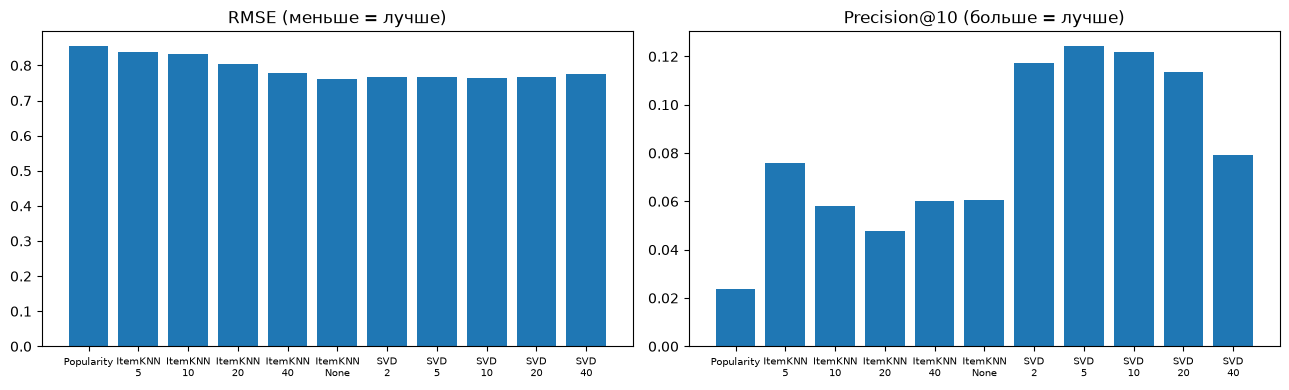

In [18]:
labels = [f"{r.model}\n{list(r.params.values())[0] if r.params else ''}" for r in cf_results.itertuples()]
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].bar(labels, cf_results["RMSE"]);  ax[0].set_title("RMSE (меньше = лучше)")
ax[1].bar(labels, cf_results["P@10"]);  ax[1].set_title("Precision@10 (больше = лучше)")
for a in ax: a.tick_params(axis="x", labelsize=7)
plt.tight_layout(); plt.show()

In [19]:
# Обучаем лучшую конфигурацию на всех доступных оценках после выбора по отложенной тестовой выборке.
best = cf_results.sort_values(["P@10", "RMSE"], ascending=[False, True]).iloc[0]
MODEL_REGISTRY = {"Popularity": PopularityModel, "ItemKNN": ItemKNN, "SVD": SVDModel}

collaborative_model_choice = (best["model"], best["params"])
print("Выбрана CF-модель:", collaborative_model_choice)

full_rating_matrix = to_matrix(ratings)
cf_model = MODEL_REGISTRY[collaborative_model_choice[0]](**collaborative_model_choice[1]).fit(full_rating_matrix)
collaborative_predictions = cf_model.predict()

Выбрана CF-модель: ('SVD', {'rank': 5})


## 5. Единый сервис `MovieRecommender`

Класс с четырьмя методами из задания 4.1: именно его потом оборачиваем в API.
Методы возвращают списки словарей (готовый JSON).

In [20]:
# Единый интерфейс объединяет контентные рекомендации и коллаборативные предсказания.
class MovieRecommender:
    def __init__(self, movie_data, content_similarity_matrix, collaborative_predictions, ratings_seen_matrix, user_ids, collaborative_model_name=""):
        self.movies = movie_data.reset_index(drop=True)
        self.content_similarity_matrix = content_similarity_matrix
        self.collaborative_predictions = collaborative_predictions
        self.ratings_seen_matrix = ratings_seen_matrix
        self.user_id_to_index = {int(u): i for i, u in enumerate(user_ids)}
        self.collaborative_model_name = collaborative_model_name
        self.normalized_titles = self.movies["title"].str.lower()
        self.genres = sorted({g for gs in self.movies["genre_list"] for g in gs})

    def _pack(self, idx, scores=None):
        out = []
        for j, i in enumerate(idx):
            row = self.movies.loc[i]
            item = {"title": row["title"],
                    "year": None if pd.isna(row["year"]) else int(row["year"]),
                    "genres": list(row["genre_list"]),
                    "imdb_rating": float(row["imdb_rating"])}
            if scores is not None:
                item["score"] = round(float(scores[j]), 4)
            out.append(item)
        return out

    def find_title(self, query):
        q = query.strip().lower()
        hit = self.normalized_titles[self.normalized_titles == q]
        if len(hit): return int(hit.index[0])
        hit = self.normalized_titles[self.normalized_titles.str.contains(re.escape(q), regex=True)]
        if len(hit): return int(hit.index[0])
        close = difflib.get_close_matches(q, self.normalized_titles.tolist(), n=1, cutoff=0.5)
        if close: return int(self.normalized_titles[self.normalized_titles == close[0]].index[0])
        raise ValueError(f"Фильм '{query}' не найден")

    def top_popular(self, n=10):
        d = self.movies.sort_values("wr", ascending=False).head(n)
        return self._pack(d.index, d["wr"].values)

    def by_genre(self, genre, n=10):
        g = genre.strip().lower()
        mask = self.movies["genre_list"].apply(lambda gs: g in [x.lower() for x in gs])
        if not mask.any():
            raise ValueError(f"Нет жанра '{genre}'. Доступные: {self.genres}")
        d = self.movies[mask].sort_values("wr", ascending=False).head(n)
        return self._pack(d.index, d["wr"].values)

    def by_title(self, title, n=10):
        i = self.find_title(title)
        s = self.content_similarity_matrix[i].copy(); s[i] = -1
        idx = np.argsort(-s)[:n]
        return self._pack(idx, s[idx])

    def by_user(self, user_id, n=10):
        if int(user_id) not in self.user_id_to_index:
            raise ValueError(f"Неизвестный пользователь {user_id}")
        u = self.user_id_to_index[int(user_id)]
        scores = np.where(self.ratings_seen_matrix[u] > 0, -np.inf, self.collaborative_predictions[u])
        idx = np.argsort(-scores)[:n]
        return self._pack(idx, scores[idx])

rec = MovieRecommender(movies, similarity_matrices[best_content_model], collaborative_predictions, full_rating_matrix, user_ids, collaborative_model_name=str(collaborative_model_choice))

In [21]:
print("1) Топ-10:");              [print("  ", x["title"], x["score"]) for x in rec.top_popular()]
print("2) Жанр Drama:");          [print("  ", x["title"], x["score"]) for x in rec.by_genre("Drama", 5)]
print("3) Похожие на 'Inception':"); [print("  ", x["title"], x["score"]) for x in rec.by_title("Inception", 5)]
uid = int(user_ids[0])
print(f"4) CF для пользователя {uid}:"); [print("  ", x["title"], x["score"]) for x in rec.by_user(uid, 5)]

1) Топ-10:
   The Shawshank Redemption 9.0237
   The Godfather 8.8917
   The Dark Knight 8.8867
   The Lord of the Rings: The Return of the King 8.768
   Schindler's List 8.7241
   The Godfather Part II 8.716
   The Lord of the Rings: The Fellowship of the Ring 8.7111
   Inception 8.6729
   Fight Club 8.6666
   Forrest Gump 8.6624
2) Жанр Drama:
   The Shawshank Redemption 9.0237
   The Godfather 8.8917
   The Dark Knight 8.8867
   The Lord of the Rings: The Return of the King 8.768
   Schindler's List 8.7241
3) Похожие на 'Inception':
   The Prestige 0.3499
   Interstellar 0.3029
   The Dark Knight 0.2918
   Batman Begins 0.2847
   The Matrix 0.2778
4) CF для пользователя 1:
   Terminator 2: Judgment Day 4.7891
   The Godfather 4.5907
   2001: A Space Odyssey 4.5818
   Die Hard 4.5733
   The Godfather Part II 4.5614


[None, None, None, None, None]

## 6. Сохранение артефактов для API

Сохраняем:
- таблицу фильмов `movies.csv` (включая IMDb рейтинг, описание и URL постера TMDB);
- матрицу похожести контентной модели;
- предсказания коллаборативной модели;
- матрицу уже просмотренных/оценённых фильмов;
- список пользователей и метаданные конфигурации.

Массивы сохраняются и в `.npy` для быстрой загрузки Python-сервисом, и в `.csv` для просмотра. Модель не нужно переобучать при каждом запуске API.

In [22]:
# Сохраняем матрицы, предсказания и метаданные, чтобы модель можно было использовать отдельно от ноутбука.
artifacts_dir = ARTIFACTS_DIR
artifacts_dir.mkdir(parents=True, exist_ok=True)

np.save(artifacts_dir / "user_ids.npy", user_ids)
np.save(artifacts_dir / "cf_pred.npy", collaborative_predictions)
np.save(artifacts_dir / "r_seen.npy", full_rating_matrix)
np.save(artifacts_dir / "content_sim.npy", similarity_matrices[best_content_model])

movies.to_csv(artifacts_dir / "movies.csv", index=False, encoding="utf-8-sig")

pd.DataFrame({"user_id": user_ids}).to_csv(
    artifacts_dir / "user_ids.csv", index=False
)

collaborative_predictions_df = pd.DataFrame(
    collaborative_predictions,
    index=user_ids,
    columns=[f"movie_{i}" for i in range(collaborative_predictions.shape[1])]
)
collaborative_predictions_df.index.name = "user_id"
collaborative_predictions_df.to_csv(artifacts_dir / "cf_pred.csv")

seen_ratings_df = pd.DataFrame(
    full_rating_matrix,
    index=user_ids,
    columns=[f"movie_{i}" for i in range(full_rating_matrix.shape[1])]
)
seen_ratings_df.index.name = "user_id"
seen_ratings_df.to_csv(artifacts_dir / "r_seen.csv")

content_similarity_df = pd.DataFrame(
    similarity_matrices[best_content_model],
    columns=[f"movie_{i}" for i in range(similarity_matrices[best_content_model].shape[1])]
)
content_similarity_df.index.name = "movie_index"
content_similarity_df.to_csv(artifacts_dir / "content_sim.csv")

metadata = {
    "content_model": best_content_model,
    "collaborative_model": str(collaborative_model_choice),
    "movies_count": int(len(movies)),
    "users_count": int(len(user_ids)),
    "ratings_count": int(len(ratings)),
    "tmdb_metadata_file": str(TMDB_CACHE_FILE)
}
with open(artifacts_dir / "model_metadata.json", "w", encoding="utf-8") as file:
    json.dump(metadata, file, ensure_ascii=False, indent=2)

print("Артефакты успешно сохранены в:", artifacts_dir.resolve())
print("Файлы:", sorted(path.name for path in artifacts_dir.iterdir()))

Артефакты успешно сохранены в: C:\Users\Svetlana\Project\movie_recommender\artifacts
Файлы: ['.ipynb_checkpoints', 'cf_pred.csv', 'cf_pred.npy', 'content_sim.csv', 'content_sim.npy', 'meta.json', 'model_metadata.json', 'movies.csv', 'r_seen.csv', 'r_seen.npy', 'user_ids.csv', 'user_ids.npy']
